# Validación en contextos reales o simulados

**Universidad de Especialidades Espíritu Santo (UEES)** · Maestría en Inteligencia Artificial
**Proyecto Integrador en Inteligencia Artificial (MIAR0545)** · Semana 5
**Autor:** Jairo Wladimir Jhayya Perlaza · **Docente:** Gladys María Villegas Rugel · **Fecha:** octubre de 2026

**Proyecto:** Análisis comparativo de modelos de aprendizaje automático y arquitecturas Transformer para la clasificación
de tráfico de red cifrado sobre el dataset CESNET-TLS-Year22.

Este notebook adapta los dos workshops de la semana al proyecto. Sigue la misma estructura del notebook de apoyo de la
clase: una parte 0 con el baseline y la evaluación con intervalos de confianza, el Workshop 1 de escenarios críticos, el
Workshop 2 de sensibilidad de hiperparámetros y un cierre con la evaluación final. Agrega dos secciones propias del
proyecto: un análisis de errores con equidad por categoría y la respuesta al comentario que la docente hizo sobre la
actividad de la semana 3.

## Cómo leer este notebook

El caso de la clase (tumores de mama) se entrena en segundos. El nuestro no: el dataset tiene 23 categorías de
servicio y cientos de miles de flujos, y un solo entrenamiento de XGBoost con todo septiembre tarda unos 90 minutos.
Por eso el trabajo se separó en dos partes.

1. **El cómputo** se ejecutó con scripts, en tres noches, y dejó sus resultados en la carpeta `results/`. El código
   está en `src/evaluate.py` (métricas, escenarios y estadística), `src/train.py` (optimización) y en los scripts
   `12_semana5_robustez.py`, `13_optuna_xgboost.py` y `09_diagnostico.py`.
2. **Este notebook** lee esos resultados, los presenta y los interpreta. No vuelve a entrenar nada, así que se ejecuta
   en pocos segundos y cualquiera puede revisarlo.

Para repetir el cómputo completo basta con ejecutar, en el entorno del proyecto:

```bash
bash scripts/utilidades/09_correr_semana5.sh noche1   # parte 0, Workshop 1, errores y Optuna
bash scripts/utilidades/09_correr_semana5.sh noche2   # comparación, reentrenamiento y cierre
bash scripts/utilidades/09_correr_semana5.sh noche3   # redes con parada temprana real
```

## Qué se adaptó respecto del caso de la clase

Trasladar el notebook de apoyo tal cual no habría funcionado, porque nuestro problema es distinto en cuatro aspectos.
La tabla resume cada diferencia y la decisión que tomé.

| Aspecto | Caso de la clase | Este proyecto | Decisión |
|---|---|---|---|
| Tipo de problema | Binario (benigno o maligno) | 23 categorías de servicio | F1 macro como métrica principal y, como métrica del dominio, el F1 de la peor categoría |
| Tamaño | 569 muestras | 800 128 flujos en septiembre y 872 731 en octubre | Validación cruzada y Optuna sobre una submuestra estratificada de 60 000 flujos; estrés sobre 100 000 de octubre |
| Independencia de las muestras | Cada paciente es único | El 30,3 % de las secuencias de paquetes se repite | Pliegues agrupados: una misma secuencia nunca queda a la vez en entrenamiento y validación |
| Conjunto de prueba | Se usa una sola vez | Octubre ya se había consultado en la semana 3 y en la versión 2 | Las decisiones se tomaron solo con validación; octubre se usa una única vez en el cierre, y lo declaro como limitación |

## 1. Configuración

Primero se cargan las librerías y se ubica la carpeta de resultados. Todo se lee con rutas relativas a la raíz del
proyecto, así el notebook funciona en cualquier equipo que tenga el repositorio. También se define una función pequeña
para mostrar las figuras que guardaron los scripts.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, display

# La raíz del proyecto es la carpeta que contiene a notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R5 = RAIZ / "results" / "semana5"           # resultados de la semana 5
DIAG = RAIZ / "results" / "diagnostico"     # resultados del diagnóstico (semana 3 y tercera noche)

pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 60)


def leer_json(ruta):
    """Lee un archivo JSON de resultados."""
    return json.loads(Path(ruta).read_text(encoding="utf-8"))


def figura(ruta, ancho=900):
    """Muestra una figura guardada por los scripts."""
    display(Image(filename=str(ruta), width=ancho))


print("Carpeta de resultados encontrada:", R5.exists())

Carpeta de resultados encontrada: True


El workshop pide fijar los criterios **antes** de ver los resultados, para que ningún umbral se ajuste a conveniencia.
Esos criterios quedaron escritos en `configs/experiment.yaml` antes de la primera ejecución. La siguiente celda los
muestra tal como están en el archivo.

In [2]:
s5 = yaml.safe_load((RAIZ / "configs" / "experiment.yaml").read_text(encoding="utf-8"))["semana5"]

decisiones = pd.DataFrame(
    [
        ("Umbral de aceptación de los escenarios", f"caída máxima de {s5['umbral_caida_f1'] * 100:.0f} puntos de F1 macro"),
        ("Repeticiones por escenario", f"{s5['repeticiones']} semillas"),
        ("Submuestra de entrenamiento", f"{s5['muestra_entrenamiento']:,} flujos de septiembre".replace(",", " ")),
        ("Submuestra para el estrés", f"{s5['muestra_estres']:,} flujos de octubre".replace(",", " ")),
        ("Validación cruzada", f"{s5['validacion_cruzada']['pliegues']} pliegues × {s5['validacion_cruzada']['repeticiones']} repeticiones, agrupados"),
        ("Pruebas de Optuna", f"{s5['optuna']['pruebas']} como máximo, con un tope de {s5['optuna']['horas_maximas']} horas"),
    ],
    columns=["Decisión", "Valor fijado antes de ejecutar"],
)
decisiones

,Decisión,Valor fijado antes de ejecutar
0,Umbral de aceptación de los escenarios,caída máxima de 5 puntos de F1 macro
1,Repeticiones por escenario,10 semillas
2,Submuestra de entrenamiento,60 000 flujos de septiembre
3,Submuestra para el estrés,100 000 flujos de octubre
4,Validación cruzada,"5 pliegues × 3 repeticiones, agrupados"
5,Pruebas de Optuna,"60 como máximo, con un tope de 4.5 horas"


## 2. Parte 0 · Baseline y evaluación con intervalos de confianza

Antes de hablar de robustez hay que saber si el modelo aporta algo. El piso es un clasificador *dummy* que adivina al
azar respetando la proporción de cada categoría. Con 23 categorías, su F1 macro debería rondar 1/23, es decir, 0,04.

Ambos modelos se evaluaron con la misma validación cruzada agrupada de 5 pliegues repetida 3 veces, lo que da 15
mediciones por modelo. El intervalo de confianza del 95 % se calculó por *bootstrap* sobre esas 15 mediciones, igual
que en el notebook de la clase.

In [3]:
intervalos = leer_json(R5 / "parte0" / "intervalos.json")

filas = []
for modelo, metricas in intervalos.items():
    for metrica, v in metricas.items():
        filas.append({"Modelo": modelo, "Métrica": metrica, "Media": v["media"], "Desviación": v["desviacion"],
                      "IC 95 % inferior": v["ic95_bajo"], "IC 95 % superior": v["ic95_alto"]})
pd.DataFrame(filas)

,Modelo,Métrica,Media,Desviación,IC 95 % inferior,IC 95 % superior
0,dummy,f1_macro,0.0434,0.0014,0.0427,0.0441
1,dummy,f1_peor_categoria,0.0000,0.0000,0.0000,0.0000
2,xgboost_v2,f1_macro,0.8078,0.0103,0.8027,0.8132
3,xgboost_v2,f1_peor_categoria,0.5444,0.1242,0.4742,0.6026


La tabla muestra la media de cada métrica en los 15 pliegues. Para ver cuánto varía el resultado de un pliegue a otro,
el diagrama de caja es más útil que un solo número: si las cajas no se superponen, la diferencia entre modelos no
depende de qué flujos cayeron en cada pliegue.

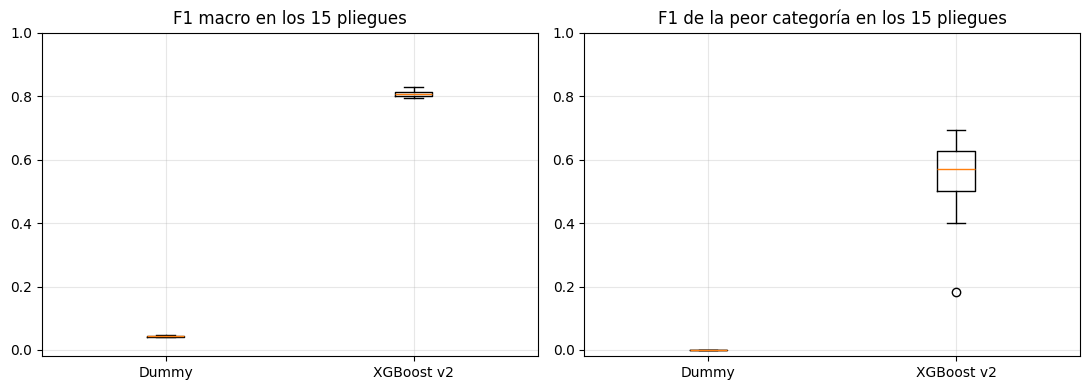

In [4]:
pliegues = pd.read_csv(R5 / "parte0" / "pliegues.csv")

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for eje, metrica, titulo in zip(ejes, ["f1_macro", "f1_peor_categoria"], ["F1 macro", "F1 de la peor categoría"]):
    datos = [pliegues.loc[pliegues.modelo == m, metrica] for m in ["dummy", "xgboost_v2"]]
    eje.boxplot(datos, tick_labels=["Dummy", "XGBoost v2"])
    eje.set_title(f"{titulo} en los 15 pliegues")
    eje.set_ylim(-0.02, 1)
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Por último, la tabla de la parte 0 del notebook de la clase compara ambos modelos sobre datos de prueba. Aquí se usan
100 000 flujos de octubre, y el modelo es el de producción (versión 2), entrenado con todo septiembre.

In [5]:
pd.read_csv(R5 / "parte0" / "tabla_octubre.csv").drop(columns=["peor_categoria"])

,modelo,accuracy,f1_macro,recall_macro,precision_macro,f1_peor_categoria,auc_ovr,auc_pr
0,dummy,0.0652,0.0436,0.0437,0.0437,0.000,0.5001,0.0435
1,xgboost_v2 (producción),0.8982,0.9009,0.9008,0.9020,0.822,0.9962,0.9560


**Lectura.** XGBoost supera al piso por más de 75 puntos de F1 macro (0,808 frente a 0,043 en validación cruzada), y
su intervalo de confianza es estrecho: de 0,803 a 0,813. El modelo aprende de verdad.

Llama la atención que el F1 en octubre (0,901) sea mayor que en la validación cruzada (0,808). No es una
contradicción: la validación cruzada entrena con 48 000 flujos por pliegue, mientras que el modelo de producción usó
640 102. Es la misma relación entre cantidad de datos y desempeño que mostró la curva por tamaño de la semana 3.

El F1 de la peor categoría, en cambio, varía mucho entre pliegues (de 0,18 a 0,69). Con submuestras pequeñas, las
categorías con pocos flujos quedan muy poco representadas, y su resultado depende de qué ejemplos tocaron. Esto
anticipa que la peor categoría será la métrica más difícil de mejorar.

## 3. Workshop 1 · Simulación de escenarios críticos

La pregunta del workshop es qué pasa cuando los datos de producción no se parecen a los de entrenamiento. Cada
escenario altera los datos de prueba de una forma controlada y mide cuánto cae el desempeño del modelo de producción.
El umbral de aceptación es una caída máxima de 5 puntos de F1 macro, fijado antes de ejecutar.

Los escenarios del notebook de la clase se adaptaron al tráfico de red:

| Escenario | Qué simula en una red real |
|---|---|
| A · Ruido genérico | Ruido gaussiano en todas las variables continuas, como en el notebook de la clase |
| A' · Ruido realista | Variaciones del 5 al 20 % en tiempos y bytes (*jitter*, retransmisiones); los conteos de paquetes no cambian |
| B · Faltantes | Campos que el exportador de flujos no envía y que se reemplazan por la mediana |
| C · Dominancia | Un servicio pasa a ocupar la mayor parte del tráfico, por ejemplo en horas pico |
| D · Cambio de distribución | El modelo se entrena con flujos cortos y se usa con flujos largos; además, la deriva real hasta diciembre |
| E · Variable caída | Las tres variables más importantes del modelo dejan de llegar |
| F · Relleno de paquetes | Escenario propio (TAREA 2), descrito más adelante |

Cada escenario se repitió con 10 semillas distintas y la tabla muestra el promedio.

In [6]:
config_w1 = leer_json(R5 / "workshop1" / "configuracion.json")
print("F1 macro sin perturbar:", round(config_w1["f1_base"], 4))
print("Categoría que se hace dominar en el escenario C:", config_w1["categoria_dominante"])
print("Las tres variables más importantes (escenario E):", ", ".join(config_w1["variables_top3"]))

F1 macro sin perturbar: 0.9009
Categoría que se hace dominar en el escenario C: Social
Las tres variables más importantes (escenario E): FLAG_RST_REV, PHIST_DST_SIZES_2, PHIST_SRC_SIZES_4


La tabla completa reúne todos los escenarios. La columna `caida_f1` es la pérdida respecto del modelo sin perturbar y
`veredicto` aplica el umbral. En el escenario D la caída se mide respecto de su propia referencia, porque ahí se compara
un mismo modelo en dos poblaciones distintas.

In [7]:
escenarios = pd.read_csv(R5 / "workshop1" / "resumen_escenarios.csv")
columnas = ["escenario", "nivel", "f1_macro", "f1_peor_categoria", "accuracy", "recall_macro", "precision_macro",
            "caida_f1", "veredicto"]
escenarios[columnas]

,escenario,nivel,f1_macro,f1_peor_categoria,accuracy,recall_macro,precision_macro,caida_f1,veredicto
0,Base,sin perturbar,0.9009,0.8220,0.8982,0.9008,0.9020,0.0000,OK
1,A · Ruido,σ=0.25,0.0780,0.0017,0.1213,0.0891,0.1566,0.8229,FALLA
2,A · Ruido,σ=0.5,0.0554,0.0000,0.0964,0.0679,0.0913,0.8455,FALLA
3,A · Ruido,σ=1.0,0.0439,0.0000,0.0817,0.0562,0.0656,0.8570,FALLA
4,A · Ruido,σ=1.5,0.0399,0.0000,0.0766,0.0525,0.0590,0.8610,FALLA
5,A' · Ruido realista,±5 % en tiempos y bytes,0.8735,0.7757,0.8716,0.8723,0.8760,0.0274,OK
6,A' · Ruido realista,±10 % en tiempos y bytes,0.8555,0.7631,0.8556,0.8525,0.8608,0.0454,OK
7,A' · Ruido realista,±20 % en tiempos y bytes,0.8233,0.7163,0.8268,0.8170,0.8354,0.0776,FALLA
8,B · Faltantes,10 %,0.8215,0.7286,0.8213,0.8135,0.8325,0.0794,FALLA
9,B · Faltantes,30 %,0.5585,0.3703,0.5763,0.5336,0.6173,0.3424,FALLA


La figura resume cómo evoluciona cada métrica a medida que aumenta la perturbación. Conviene mirar en especial el panel
de dominancia: ahí la exactitud se mantiene casi plana mientras el F1 macro cae.

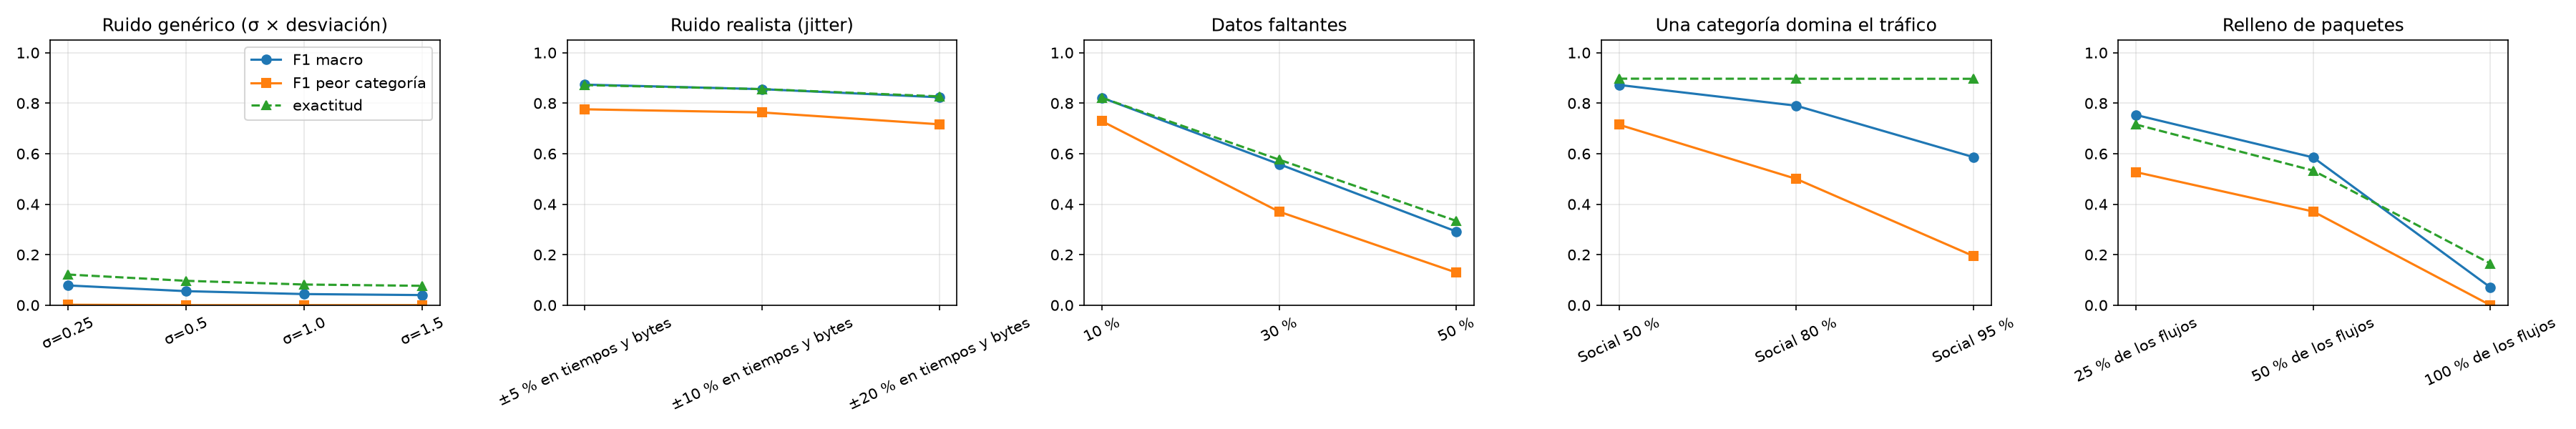

In [8]:
figura(R5 / "workshop1" / "escenarios.png", ancho=1100)

### TAREA 1

**1. ¿Qué escenario degrada más el recall y cuál la precisión?**

Dejando de lado el ruido genérico, que destruye ambas métricas por igual, los escenarios afectan a cada una de forma
muy distinta. El relleno de paquetes y los datos faltantes golpean más al recall: con el 30 % de faltantes el recall
macro baja a 0,534 y la precisión a 0,617, y con el relleno total el recall cae a 0,089. El modelo deja de reconocer
los servicios y los confunde con otros.

La dominancia hace lo contrario. Cuando Social ocupa el 95 % del tráfico, el recall macro se queda en 0,900, igual que
sin perturbar, pero la precisión macro se desploma de 0,902 a 0,478. La razón es que el recall de cada categoría se
mide dentro de esa categoría y no cambia con la proporción. En cambio, los pocos errores que el modelo comete sobre
Social se convierten, por volumen, en muchísimos falsos positivos para las demás categorías.

**2. ¿Por qué la exactitud engaña en el escenario de desbalance?**

Porque la exactitud cuenta flujos, no categorías. Con Social en el 95 % del tráfico, la exactitud es 0,896, casi la
misma que sin perturbar (0,898), y daría la impresión de que nada cambió. En realidad, el F1 macro cae de 0,901 a
0,586 y el F1 de la peor categoría a 0,195. La exactitud termina midiendo, sobre todo, qué tan bien se clasifica
Social. Por eso el proyecto usa el F1 macro, que da el mismo peso a las 23 categorías.

**3. ¿Qué diferencia hay entre el subgrupo de referencia y el distinto? ¿Qué harías en producción?**

Un modelo entrenado solo con flujos cortos obtiene 0,838 en flujos cortos que no vio, pero apenas 0,301 en flujos
largos: una caída de 53,6 puntos. Los flujos largos tienen duraciones, volúmenes y conteos de paquetes fuera del rango
que el modelo conoció, y los árboles de decisión no extrapolan: asignan a cualquier valor mayor el comportamiento del
extremo que sí vieron. La deriva real de octubre a diciembre, en cambio, cuesta 4,6 puntos y queda dentro del umbral.

En producción haría tres cosas: asegurar que el entrenamiento cubra toda la población de flujos, vigilar cada mes la
distribución de las variables de entrada (el proyecto ya mide la divergencia de Jensen-Shannon entre meses) y, cuando
un flujo cae fuera del rango conocido, abstenerse de clasificarlo en lugar de dar una respuesta poco confiable.

**4. ¿Qué escenarios fallan el criterio y qué mitigación propones?**

| Escenario que falla | Mitigación propuesta |
|---|---|
| A · Ruido genérico | No refleja la red real (ver la sección siguiente), pero revela que el modelo depende de los valores exactos de los conteos. Mitigación: entrenar con aumento de datos que respete el carácter discreto de esas variables |
| A' · Ruido realista del 20 % | Entrenar con variaciones simuladas de tiempos y bytes, para que el modelo aprenda a tolerarlas |
| B · Faltantes desde el 10 % | Dejar los valores ausentes como faltantes en lugar de imputar la mediana: XGBoost sabe manejarlos de forma nativa y aprende a qué rama enviarlos |
| C · Dominancia desde el 80 % | Reportar siempre el F1 por categoría y recalibrar los umbrales de decisión cuando cambie la composición del tráfico |
| D · Flujos largos | Cubrir toda la población al entrenar, monitorear la deriva y abstenerse fuera del rango conocido |
| F · Relleno de paquetes | Ver la TAREA 2 |

El escenario E pasa, pero en el límite: sin las tres variables más importantes la caída es exactamente de 5,0 puntos.
El modelo tiene cierta redundancia, aunque no mucha.

### Ruido genérico frente a ruido realista

El ruido genérico merece una explicación aparte, porque su resultado es extremo: con apenas 0,25 desviaciones estándar
el F1 macro cae de 0,901 a 0,078, casi al nivel del *dummy*. Al revisarlo encontré la causa. Muchas de las 60 variables
son conteos, por ejemplo cuántos paquetes cayeron en cada intervalo de tamaño. Sumarles ruido gaussiano produce valores
como −0,3 paquetes, que no existen en ningún flujo real, y los árboles de XGBoost separan justamente entre "cero" y "más
de cero" en esas variables.

Por eso agregué el escenario A', que altera solo lo que una red sí altera: los tiempos y los bytes. La comparación
cambia por completo la conclusión.

In [9]:
ruidos = escenarios[escenarios.escenario.isin(["A · Ruido", "A' · Ruido realista"])]
ruidos[["escenario", "nivel", "f1_macro", "caida_f1", "veredicto"]]

,escenario,nivel,f1_macro,caida_f1,veredicto
1,A · Ruido,σ=0.25,0.0780,0.8229,FALLA
2,A · Ruido,σ=0.5,0.0554,0.8455,FALLA
3,A · Ruido,σ=1.0,0.0439,0.8570,FALLA
4,A · Ruido,σ=1.5,0.0399,0.8610,FALLA
5,A' · Ruido realista,±5 % en tiempos y bytes,0.8735,0.0274,OK
6,A' · Ruido realista,±10 % en tiempos y bytes,0.8555,0.0454,OK
7,A' · Ruido realista,±20 % en tiempos y bytes,0.8233,0.0776,FALLA


El modelo tolera variaciones realistas del 5 y del 10 % en tiempos y bytes, que son las habituales en una red, y solo
falla con el 20 %. Su fragilidad está en los conteos, que en una red real no se alteran con ruido. Es un hallazgo útil:
la robustez se debe medir con perturbaciones que tengan sentido en el dominio.

### TAREA 2 · Escenario propio: relleno de paquetes

**Por qué este escenario.** El relleno de paquetes (*padding*) consiste en agrandar cada paquete hasta un tamaño fijo,
normalmente la unidad máxima de transmisión de 1 500 bytes. Es una técnica real con dos caras. Un atacante puede usarla
para que su tráfico no sea reconocido, y un servicio que protege la privacidad de sus usuarios puede usarla para que
nadie infiera qué están haciendo. En el informe ético de la semana 4 quedó como el riesgo R5, la evasión, y no se había
evaluado.

**Cómo se simuló.** En una fracción de los flujos, cada paquete pasa a medir 1 500 bytes. Sobre las variables del
modelo eso significa que los bytes enviados y recibidos pasan a ser el número de paquetes por 1 500, y que los
histogramas de tamaños concentran todos los paquetes en el intervalo más grande. Los tiempos y las banderas no cambian.
Se probó con el 25, el 50 y el 100 % de los flujos rellenados.

In [10]:
escenarios[escenarios.escenario.str.startswith("F")][["nivel", "f1_macro", "f1_peor_categoria", "accuracy", "caida_f1", "veredicto"]]

,nivel,f1_macro,f1_peor_categoria,accuracy,caida_f1,veredicto
18,25 % de los flujos,0.7532,0.5269,0.7155,0.1477,FALLA
19,50 % de los flujos,0.5850,0.3709,0.5331,0.3159,FALLA
20,100 % de los flujos,0.0704,0.0000,0.1649,0.8305,FALLA


**Lectura.** Basta con que uno de cada cuatro flujos esté rellenado para que el F1 macro caiga 14,8 puntos, hasta
0,753. Si se rellenan todos, el modelo queda en 0,070, prácticamente inútil. El tamaño de los paquetes es la
información de la que más depende el clasificador.

La conclusión tiene una lectura técnica y otra ética. En lo técnico, el clasificador no es robusto frente a la evasión
deliberada, y ningún reentrenamiento lo resolvería del todo, porque el relleno elimina justamente la señal que se usa.
En lo ético, el resultado confirma que el relleno es una defensa eficaz de la privacidad frente a este tipo de
sistemas. Ambas cosas deben quedar declaradas como limitación del proyecto.

## 4. Workshop 2 · Sensibilidad de hiperparámetros

El objetivo de este workshop no es solo encontrar la mejor configuración, sino entender qué hiperparámetros importan.
Se optimizó XGBoost, el modelo de producción, con Optuna y su muestreador TPE con semilla fija. Cada prueba se evaluó
con validación cruzada agrupada de 3 pliegues sobre los 60 000 flujos de septiembre, sin tocar octubre.

El estudio tenía un tope de 4,5 horas. Alcanzó 41 pruebas de las 60 previstas: 28 terminaron y 13 se abandonaron tras el
primer pliegue porque iban claramente peor que la mediana de las anteriores, un mecanismo que se llama poda.

In [11]:
resumen_optuna = leer_json(R5 / "optuna" / "resumen.json")
print("Pruebas por estado:", resumen_optuna["pruebas"])
print("Rango del F1 en las pruebas completas:", [round(v, 4) for v in resumen_optuna["rango_f1_completas"]])
print("Mejor F1 (validación cruzada):", round(resumen_optuna["mejor_f1_cv"], 4))
print("Mejores hiperparámetros:")
for nombre, valor in resumen_optuna["mejores_parametros"].items():
    print(f"   {nombre:<18} {valor:.4g}")

Pruebas por estado: {'COMPLETE': 28, 'PRUNED': 13}
Rango del F1 en las pruebas completas: [0.7057, 0.8079]
Mejor F1 (validación cruzada): 0.8079
Mejores hiperparámetros:
   max_depth          11
   learning_rate      0.09528
   subsample          0.6291
   colsample_bytree   0.8287
   reg_lambda         2.565
   min_child_weight   2


La tabla siguiente muestra las diez mejores pruebas. Sirve para ver si la mejor configuración es un caso aislado o si
hay una zona del espacio que funciona de forma consistente.

In [12]:
pruebas = pd.read_csv(R5 / "optuna" / "pruebas.csv")
parametros = [c for c in pruebas.columns if c.startswith("params_")]
mejores = pruebas[pruebas.state == "COMPLETE"].sort_values("value", ascending=False).head(10)
mejores[["number", "value"] + parametros].rename(columns=lambda c: c.replace("params_", ""))

,number,value,colsample_bytree,learning_rate,max_depth,min_child_weight,reg_lambda,subsample
40,40,0.8079,0.8287,0.0953,11,2,2.5646,0.6291
38,38,0.8061,0.8178,0.0816,11,1,5.8856,0.6782
34,34,0.8052,0.7914,0.1000,10,1,3.9502,0.6271
35,35,0.8051,0.8346,0.0871,11,2,2.9354,0.6480
29,29,0.8044,0.8491,0.0870,10,3,3.5207,0.6632
37,37,0.8038,0.8687,0.1061,12,1,7.4236,0.6228
32,32,0.8022,0.9234,0.1271,8,3,1.0188,0.8093
4,4,0.8011,0.7571,0.1445,7,1,2.3076,0.5998
36,36,0.8010,0.8836,0.1363,11,3,3.5292,0.6633
25,25,0.8006,0.8287,0.2073,9,2,3.6088,0.6766


El historial muestra cómo avanzó la búsqueda. Las primeras pruebas son exploratorias y dispersas. El mejor valor se
quedó en 0,8011 desde la prueba 4 hasta la 28; a partir de la 29, cuando el muestreador ya concentraba la búsqueda en la
zona prometedora, mejoró cuatro veces hasta llegar a 0,8079 en la prueba 40.

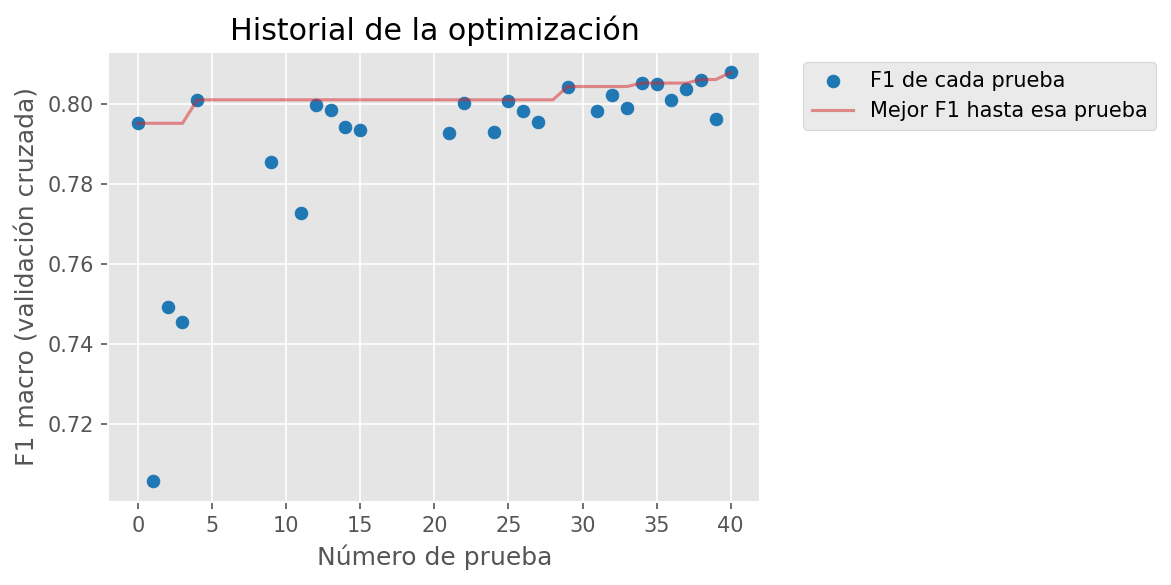

In [13]:
figura(R5 / "optuna" / "historial.png", ancho=750)

La importancia de cada hiperparámetro se calculó con dos métodos distintos: fANOVA, que descompone la varianza del F1,
y la reducción de impureza de un bosque aleatorio. Si los dos coinciden, la conclusión no depende del método.

,fANOVA,Reducción de impureza
min_child_weight,55.6%,51.4%
colsample_bytree,14.8%,14.3%
reg_lambda,11.1%,16.3%
max_depth,8.4%,7.6%
learning_rate,7.1%,7.6%
subsample,2.9%,2.8%


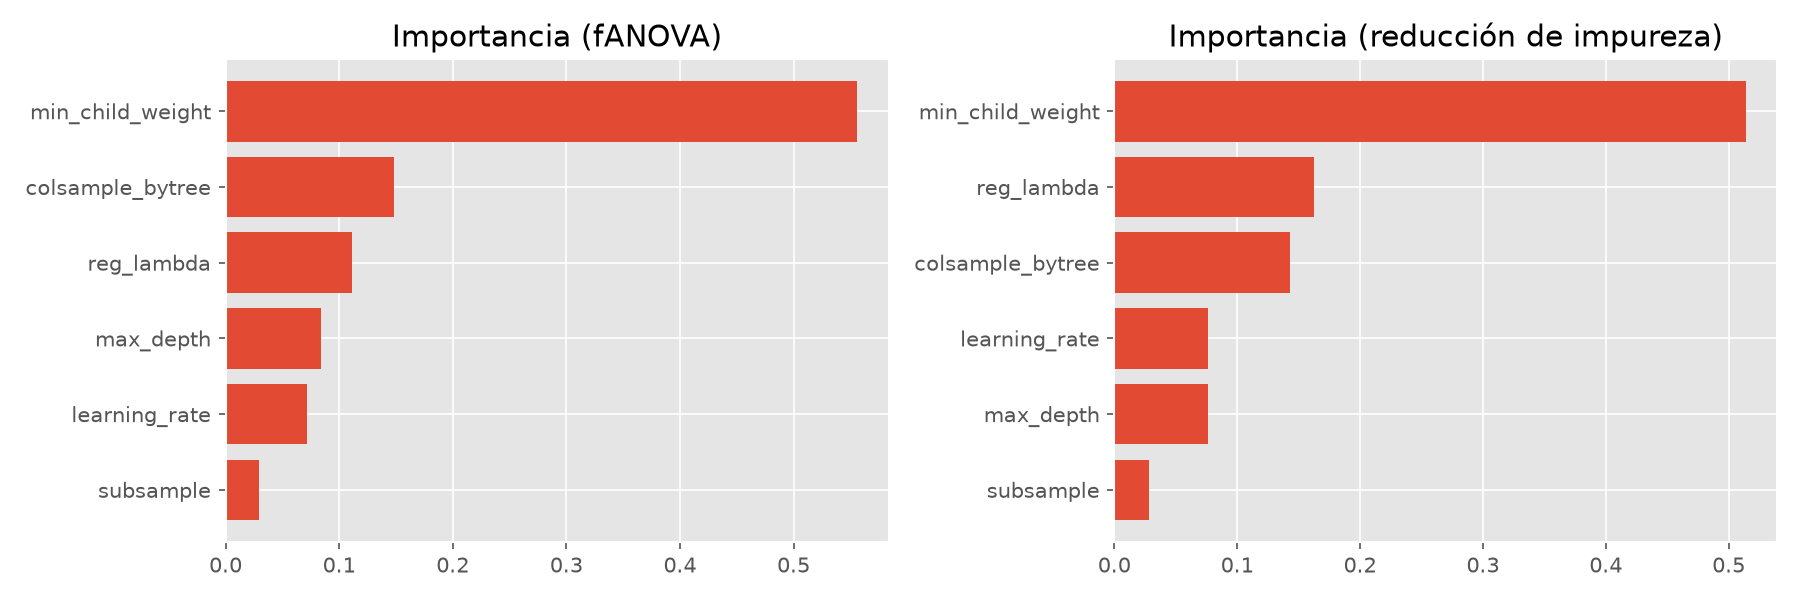

In [14]:
importancias = pd.DataFrame(resumen_optuna["importancias"]).rename(columns={"fanova": "fANOVA", "impureza": "Reducción de impureza"})
display(importancias.sort_values("fANOVA", ascending=False).style.format("{:.1%}"))
figura(R5 / "optuna" / "importancias.png", ancho=950)

Los gráficos de *slice* muestran cada prueba según el valor de cada hiperparámetro, y la dependencia parcial resume el
efecto de cada uno sobre el F1 con un modelo sustituto entrenado sobre las pruebas.

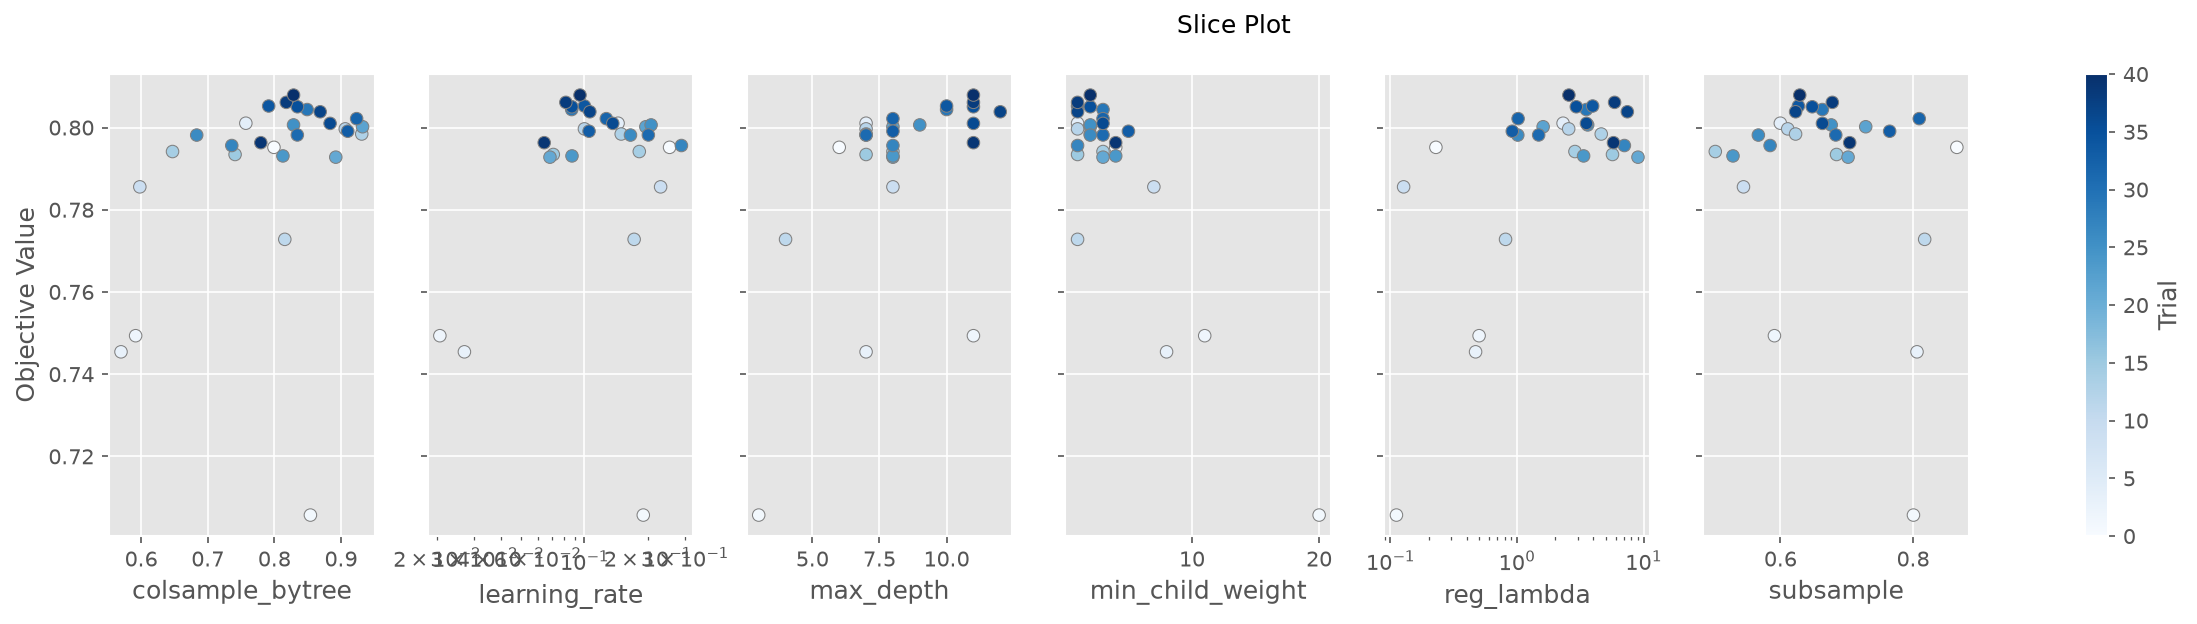

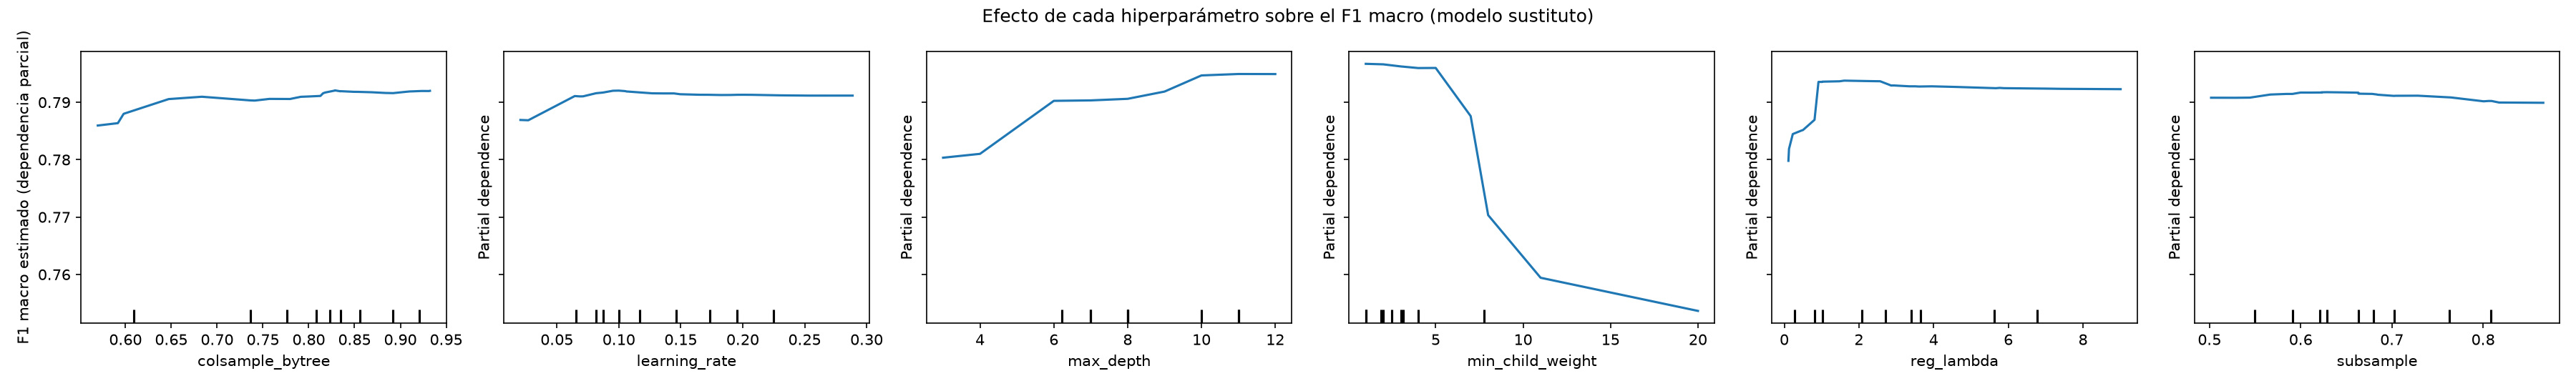

In [15]:
figura(R5 / "optuna" / "slice.png", ancho=1100)
figura(R5 / "optuna" / "dependencia_parcial.png", ancho=1100)

Finalmente, la interacción entre los dos hiperparámetros más importantes se revisa de dos formas: el contorno de las
pruebas reales y la dependencia parcial en dos dimensiones.

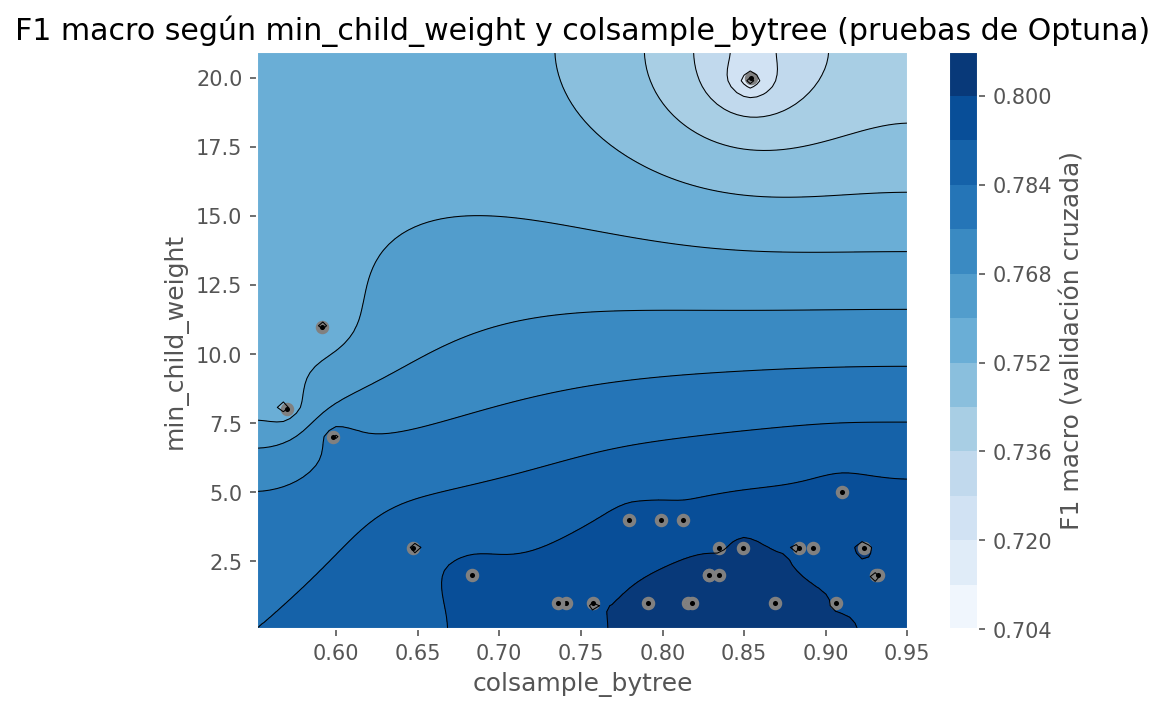

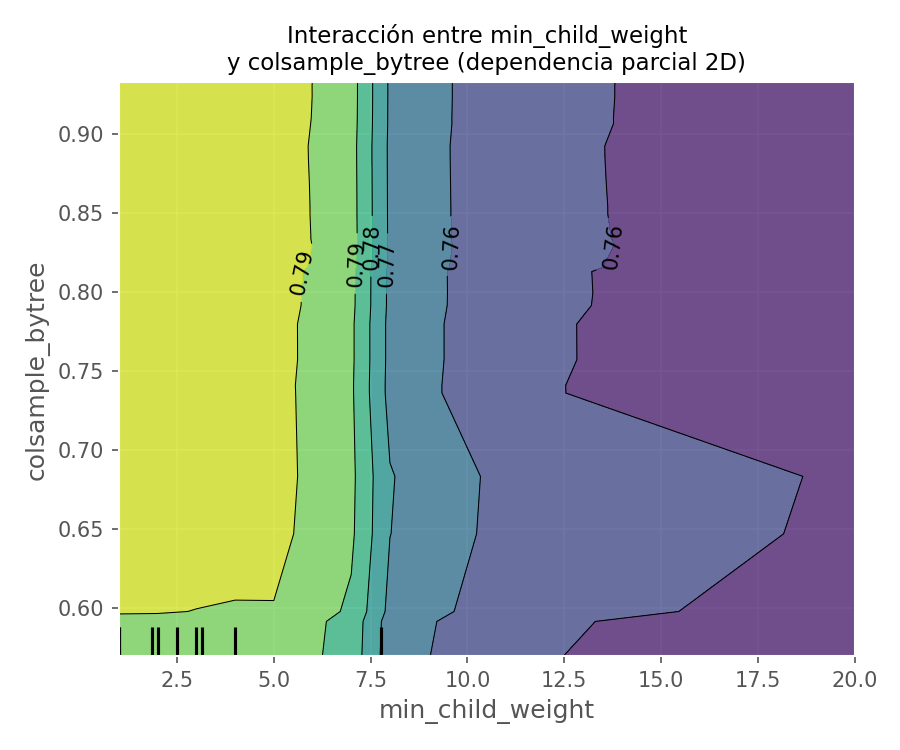

In [16]:
figura(R5 / "optuna" / "contorno.png", ancho=620)
figura(R5 / "optuna" / "dependencia_parcial_2d.png", ancho=520)

### TAREA 3

**1. ¿Qué hiperparámetros importan y cuáles no? ¿Las diferencias de F1 son grandes?**

`min_child_weight` domina con claridad: explica el 56 % de la variación según fANOVA y el 51 % según la reducción de
impureza. Le siguen, muy por detrás, `colsample_bytree`, `reg_lambda`, `max_depth` y `learning_rate`, mientras que
`subsample` apenas influye (alrededor del 3 %). Los dos métodos coinciden en el más importante y en el menos
importante; en el medio cambian el orden, porque fANOVA pone segundo a `colsample_bytree` (15 %) y la reducción de
impureza a `reg_lambda` (16 %). Esa coincidencia en los extremos es la que da solidez a la conclusión.

Las diferencias dependen de dónde se mire. Entre la peor y la mejor prueba completa hay 10 puntos de F1 (de 0,706 a
0,808), una diferencia enorme. Entre las cinco mejores, en cambio, la diferencia es de apenas 0,4 puntos. Equivocarse
en `min_child_weight` cuesta mucho; afinar el resto aporta poco.

**2. ¿Hay interacción entre los dos hiperparámetros del contorno?**

Prácticamente no. En la dependencia parcial 2D las franjas de color son verticales: el F1 cambia al mover
`min_child_weight` y casi no cambia al mover `colsample_bytree`. Solo con valores de `colsample_bytree` por debajo de
0,6 el F1 baja algo más. El contorno de las pruebas reales lo confirma: la mejor zona está en `min_child_weight` bajo,
entre 1 y 5, sin importar mucho el valor del otro parámetro.

**3. ¿Qué rangos ampliarías y qué fijarías?**

`min_child_weight` conviene explorarlo por debajo de 1, como valor decimal, porque las mejores pruebas se acumulan en el
borde inferior del rango. `max_depth` debería ampliarse por encima de 12, porque su dependencia parcial sigue subiendo
en el extremo. `subsample` puede fijarse en torno a 0,65, ya que casi no influye, y `colsample_bytree` puede acotarse
entre 0,75 y 0,90. Además, el límite de 400 rondas fue corto: la mejor prueba usó en promedio 395, así que en una nueva
búsqueda habría que darle más margen a la parada temprana.

**4. ¿Por qué una diferencia de 0,002 en F1 no justifica elegir una configuración?**

Porque es menor que la variabilidad del propio método de evaluación. En la parte 0, el F1 de XGBoost varió con una
desviación de 0,011 entre pliegues y su intervalo de confianza tiene un ancho de 0,010. Una diferencia de 0,002 cabe
holgadamente dentro de ese margen y podría deberse solo a qué flujos tocaron en cada pliegue. Por eso, para decidir, no
comparé dos números sino que usé pruebas estadísticas sobre los mismos pliegues, como se muestra en el cierre.

## 5. Cierre · Evaluación final única

El cierre responde una sola pregunta: la configuración optimizada, ¿es realmente mejor que la versión 2? Se respondió
en tres pasos, cada uno con datos distintos, para que la conclusión no dependa de un único conjunto.

El primer paso compara ambas configuraciones en los mismos 15 pliegues de la parte 0, con la prueba de Wilcoxon para
muestras pareadas. Usé 15 pliegues y no 5 por una razón práctica: con solo 5 pares, el valor p más pequeño que puede
dar la prueba es 0,0625, así que nunca podría salir significativa.

In [17]:
comparacion = leer_json(R5 / "optuna" / "comparacion_cv.json")
filas = []
for metrica, datos in comparacion.items():
    filas.append({"Métrica": metrica, "Versión 2": datos["v2"]["media"], "Optimizado": datos["optimizado"]["media"],
                  "Mediana de la diferencia": datos["wilcoxon"]["mediana_diferencia"],
                  "p (Wilcoxon)": datos["wilcoxon"]["p_valor"], "Significativo": datos["wilcoxon"]["significativo"]})
pd.DataFrame(filas)

,Métrica,Versión 2,Optimizado,Mediana de la diferencia,p (Wilcoxon),Significativo
0,f1_macro,0.8078,0.8119,0.0039,0.0015,True
1,f1_peor_categoria,0.5444,0.5444,0.0000,0.9594,False


El segundo paso reentrena la mejor configuración con todo septiembre, con el mismo protocolo que la versión 2, y compara
ambas en el conjunto de validación.

In [18]:
reentrenamiento = leer_json(R5 / "optuna" / "reentrenamiento.json")
print(f"F1 macro en validación · versión 2:  {reentrenamiento['f1_macro_validacion_v2']:.4f}")
print(f"F1 macro en validación · optimizado: {reentrenamiento['validacion_optimizado']['f1_macro']:.4f}")
print(f"Mejora: {reentrenamiento['mejora_validacion_puntos']:+.2f} puntos")
print(f"Rondas usadas: {reentrenamiento['rondas_usadas']} de 1 000 · entrenamiento: {reentrenamiento['minutos_entrenamiento']:.0f} minutos")

F1 macro en validación · versión 2:  0.9159
F1 macro en validación · optimizado: 0.9239
Mejora: +0.79 puntos
Rondas usadas: 973 de 1 000 · entrenamiento: 92 minutos


El tercer paso es la evaluación final, la única vez que se usa octubre completo: 872 731 flujos. Se acompaña de dos
pruebas estadísticas: el intervalo de confianza de la diferencia de F1, calculado por *bootstrap* sobre los mismos
flujos, y la prueba de McNemar, que compara los aciertos y errores de ambos modelos flujo por flujo.

In [19]:
final = pd.read_csv(R5 / "cierre" / "evaluacion_final.csv").drop(columns=["peor_categoria"])
display(final)

cierre = leer_json(R5 / "cierre" / "comparacion.json")
d = cierre["diferencia_f1"]
print(f"Diferencia de F1 macro (optimizado − v2): {d['diferencia']:+.4f}  IC 95 % [{d['ic95_bajo']:+.4f}, {d['ic95_alto']:+.4f}]")
tabla = cierre["mcnemar"]["tabla"]
print(f"McNemar: la v2 acierta y el optimizado falla en {tabla[0][1]:,} flujos; al revés, en {tabla[1][0]:,}".replace(",", " "))
print(f"         estadístico {cierre['mcnemar']['estadistico']:.1f}, p < 0,001")

,modelo,accuracy,f1_macro,recall_macro,precision_macro,f1_peor_categoria,auc_ovr,auc_pr
0,xgboost_v2,0.9004,0.9032,0.9026,0.9048,0.8296,0.9962,0.9581
1,xgboost_optimizado,0.9083,0.9111,0.9047,0.9184,0.8404,0.9967,0.9616


Diferencia de F1 macro (optimizado − v2): +0.0078  IC 95 % [+0.0071, +0.0085]
McNemar: la v2 acierta y el optimizado falla en 9 431 flujos; al revés  en 16 246
         estadístico 1808.3, p < 0,001


Por último, se repitió la prueba de estrés con ambos modelos, para comprobar que la mejora no se obtuvo a costa de
volver al modelo más frágil.

In [20]:
estres = pd.read_csv(R5 / "cierre" / "estres_comparado.csv")
estres.pivot(index="escenario", columns="modelo", values="f1_macro").loc[
    ["sin perturbar", "ruido σ=1.0", "faltantes 30 %", "dominancia 95 %", "relleno 100 %"]]

modelo,xgboost_optimizado,xgboost_v2
escenario,,
sin perturbar,0.9093,0.9009
ruido σ=1.0,0.0466,0.0439
faltantes 30 %,0.5683,0.5585
dominancia 95 %,0.6181,0.5864
relleno 100 %,0.0670,0.0704


**Lectura.** Las tres pruebas apuntan en la misma dirección. En los 15 pliegues, la configuración optimizada gana con
una mediana de 0,39 puntos y un valor p de 0,0015. En validación mejora 0,79 puntos, y en octubre 0,78 puntos, con un
intervalo de confianza que va de +0,71 a +0,85 y no contiene el cero. McNemar lo confirma: hay 16 246 flujos que solo
acierta el modelo optimizado, frente a 9 431 que solo acierta la versión 2.

Que la mejora en validación y en octubre sea casi idéntica es una buena señal: indica que la configuración no se ajustó
en exceso a los datos con los que se eligió. Además, el modelo optimizado resiste igual o un poco mejor que la versión 2
en casi todos los escenarios de estrés; la excepción es el relleno total, donde ambos quedan prácticamente inútiles
(0,067 frente a 0,070).

Hay dos matices que conviene no ocultar. El primero: en la validación cruzada, el F1 de la peor categoría no mejoró
(0,544 en ambos casos, con p = 0,96). La optimización mejoró el promedio, no la categoría más difícil en la submuestra.
En octubre completo la peor categoría, Media, sí sube de 0,830 a 0,840. El segundo: el reentrenamiento usó 973 de las
1 000 rondas, así que la parada temprana quedó muy cerca del límite y es posible que más rondas aportaran algo más.

A diferencia del ejemplo de la clase, donde el modelo optimizado no superaba al original, aquí la optimización sí
produjo una mejora real. La lección es la misma: solo se puede afirmar con pruebas estadísticas, no comparando dos
números.

## 6. Análisis de errores y equidad entre categorías

Saber cuánto se equivoca el modelo no basta; también importa dónde y con quién se equivoca. Este análisis usa el modelo
de producción sobre todo octubre. Empieza por los pares de categorías que más se confunden.

In [21]:
pd.read_csv(R5 / "errores" / "pares_confundidos.csv").head(10)

,real,predicha,errores,fraccion_de_la_categoria,fraccion_de_todos_los_errores
0,Media,Social,2835,0.0404,0.0326
1,Social,Media,2522,0.0269,0.0290
2,Advertising,Media,2352,0.0271,0.0271
3,Media,Advertising,2072,0.0295,0.0238
4,Other APIs,Social,1861,0.0271,0.0214
5,Media,Other APIs,1843,0.0263,0.0212
6,Other services,Advertising,1615,0.0234,0.0186
7,Social,Other APIs,1598,0.0170,0.0184
8,Advertising,Social,1597,0.0184,0.0184
9,Other services,Media,1306,0.0189,0.0150


Los errores se concentran en un grupo de servicios que comparten infraestructura: Media, Social, Advertising y Other
APIs. Muchos de ellos se sirven desde las mismas redes de distribución de contenido, así que sus flujos se parecen.

La siguiente tabla divide los flujos en cinco grupos según su número de paquetes.

In [22]:
pd.read_csv(R5 / "errores" / "error_por_longitud.csv")

,paquetes_del_flujo,flujos,tasa_error,f1_macro
0,"(4.999, 19.0]",216575,0.1093,0.8751
1,"(19.0, 22.0]",134995,0.0589,0.8870
2,"(22.0, 29.0]",190329,0.0816,0.9000
3,"(29.0, 58.0]",156889,0.1052,0.8778
4,"(58.0, 2135063.0]",173943,0.1335,0.8525


El modelo se equivoca más en los extremos: en los flujos muy cortos, de 19 paquetes o menos (10,9 % de error), porque
traen poca información, y en los muy largos, de más de 58 paquetes (13,4 %), que son los más variados. Los flujos de
longitud media son los más fáciles.

La calibración responde otra pregunta: cuando el modelo dice que está seguro en un 90 %, ¿acierta el 90 % de las
veces? Es importante porque, si la confianza es fiable, se puede usar para abstenerse cuando el modelo duda, una de las
mitigaciones que comprometí en el informe ético.

,intervalo,flujos,confianza_media,acierto
0,"(0.1, 0.2]",1098,0.1807,0.1767
1,"(0.2, 0.3]",12598,0.2610,0.2735
2,"(0.3, 0.4]",26318,0.3527,0.3924
3,"(0.4, 0.5]",33795,0.4521,0.4902
4,"(0.5, 0.6]",36534,0.5497,0.5989
5,"(0.6, 0.7]",36454,0.6506,0.7076
6,"(0.7, 0.8]",42422,0.7521,0.8122
7,"(0.8, 0.9]",63467,0.8550,0.9071
8,"(0.9, 1.0]",620045,0.9859,0.9928


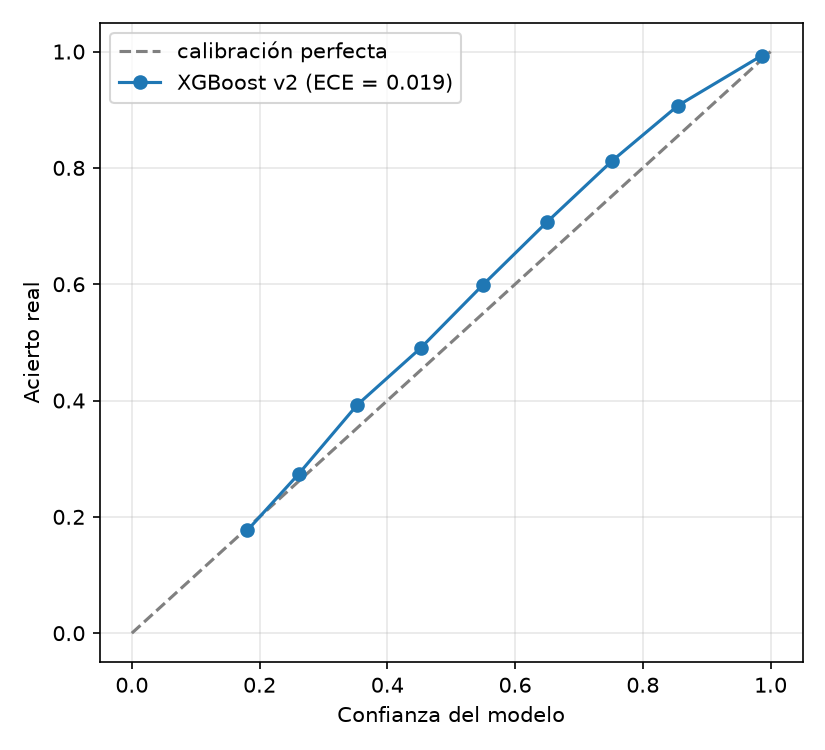

In [23]:
display(pd.read_csv(R5 / "errores" / "calibracion.csv"))
figura(R5 / "errores" / "calibracion.png", ancho=450)

El error de calibración esperado es de apenas 0,019, y la curva queda ligeramente por encima de la diagonal: el modelo
acierta un poco más de lo que dice. Su confianza es una base sólida para decidir cuándo abstenerse.

La tabla siguiente separa los flujos de octubre cuya secuencia de paquetes ya había aparecido en septiembre de los que
son completamente nuevos.

In [24]:
pd.read_csv(R5 / "errores" / "repetidas_vs_nuevas.csv")[["secuencias", "flujos", "f1_macro", "f1_peor_categoria"]]

,secuencias,flujos,f1_macro,f1_peor_categoria
0,repetidas (vistas en septiembre),264700,0.9409,0.8006
1,nuevas,608031,0.8853,0.7963


En las secuencias ya vistas el F1 macro es de 0,941; en las nuevas, de 0,885. Esa diferencia de 5,6 puntos es el
efecto de la memorización y explica por qué los pliegues de la validación cruzada debían agruparse por secuencia.

Por último, la equidad entre categorías. Como el sistema no toma decisiones sobre personas, el grupo pertinente es el
servicio: si el clasificador se usara para gestionar la red, los servicios peor clasificados recibirían peor trato. Se
calculó con `MetricFrame`, de Fairlearn.

In [25]:
equidad = pd.read_csv(R5 / "errores" / "equidad_por_categoria.csv")
brechas = leer_json(R5 / "errores" / "resumen.json")
print(f"Brecha máxima entre categorías: {brechas['diferencia_max']:.3f} · razón mínima: {brechas['razon_min']:.3f}")
display(pd.concat([equidad.head(4), equidad.tail(3)]))

Brecha máxima entre categorías: 0.160 · razón mínima: 0.838


,categoria,tasa_acierto
0,Media,0.8279
1,Virtual assistant,0.8326
2,Other services,0.8463
3,Remote desktop,0.8557
20,Software updates,0.9627
21,Analytics & Telemetry,0.9628
22,Notifications,0.9875


La categoría con menor tasa de acierto es Media (0,828) y la mejor es Notifications (0,988): una brecha de 16 puntos.
Ningún servicio queda por debajo de 0,80, pero la diferencia existe y debe reportarse junto al promedio.

## 7. Respuesta al comentario de la semana 3

En la actividad de la semana 3, la docente observó que, después de la estrategia de mejora, la CNN y el Transformer
seguían mejorando al terminar el entrenamiento y que la parada temprana nunca se activó. Propuso entrenar hasta que
actuara la parada o aumentar la capacidad de las redes.

Al revisar el código encontré dos causas. El programador OneCycle fija de antemano la duración y lleva la tasa de
aprendizaje casi a cero al final, lo que produce pequeñas mejoras constantes. Y la paciencia se reiniciaba con
cualquier mejora, por mínima que fuera. Lo corregí con un programador que reduce la tasa a la mitad solo cuando la
validación se estanca (ReduceLROnPlateau), un límite alto de épocas y una mejora mínima de 0,001 para reiniciar la
paciencia. Luego probé las dos opciones que propuso la docente sobre la misma muestra de 200 000 flujos de la semana 3.

In [26]:
redes = pd.read_csv(DIAG / "comparacion_parada.csv")
redes[["modelo", "momento", "f1_entrenamiento", "f1_validacion", "f1_prueba", "brecha", "mejor_paso",
       "epocas_ejecutadas", "parada_activada"]]

,modelo,momento,f1_entrenamiento,f1_validacion,f1_prueba,brecha,mejor_paso,epocas_ejecutadas,parada_activada
0,CNN 1D,Antes,0.6216,0.6169,0.6118,0.0047,15,15,NaN
1,CNN 1D,Después,0.7745,0.7576,0.7456,0.0169,38,40,NaN
2,CNN 1D,Parada temprana,0.7361,0.7189,0.7131,0.0173,69,72,True
3,CNN 1D,Más capacidad,0.8354,0.8041,0.7908,0.0313,89,89,True
4,Transformer,Antes,0.6645,0.6570,0.6447,0.0075,15,15,NaN
5,Transformer,Después,0.7898,0.7692,0.7570,0.0205,25,25,NaN
6,Transformer,Parada temprana,0.7799,0.7633,0.7527,0.0166,36,46,True


La figura muestra, para cada red, el F1 de validación y la tasa de aprendizaje época por época en todas las variantes.

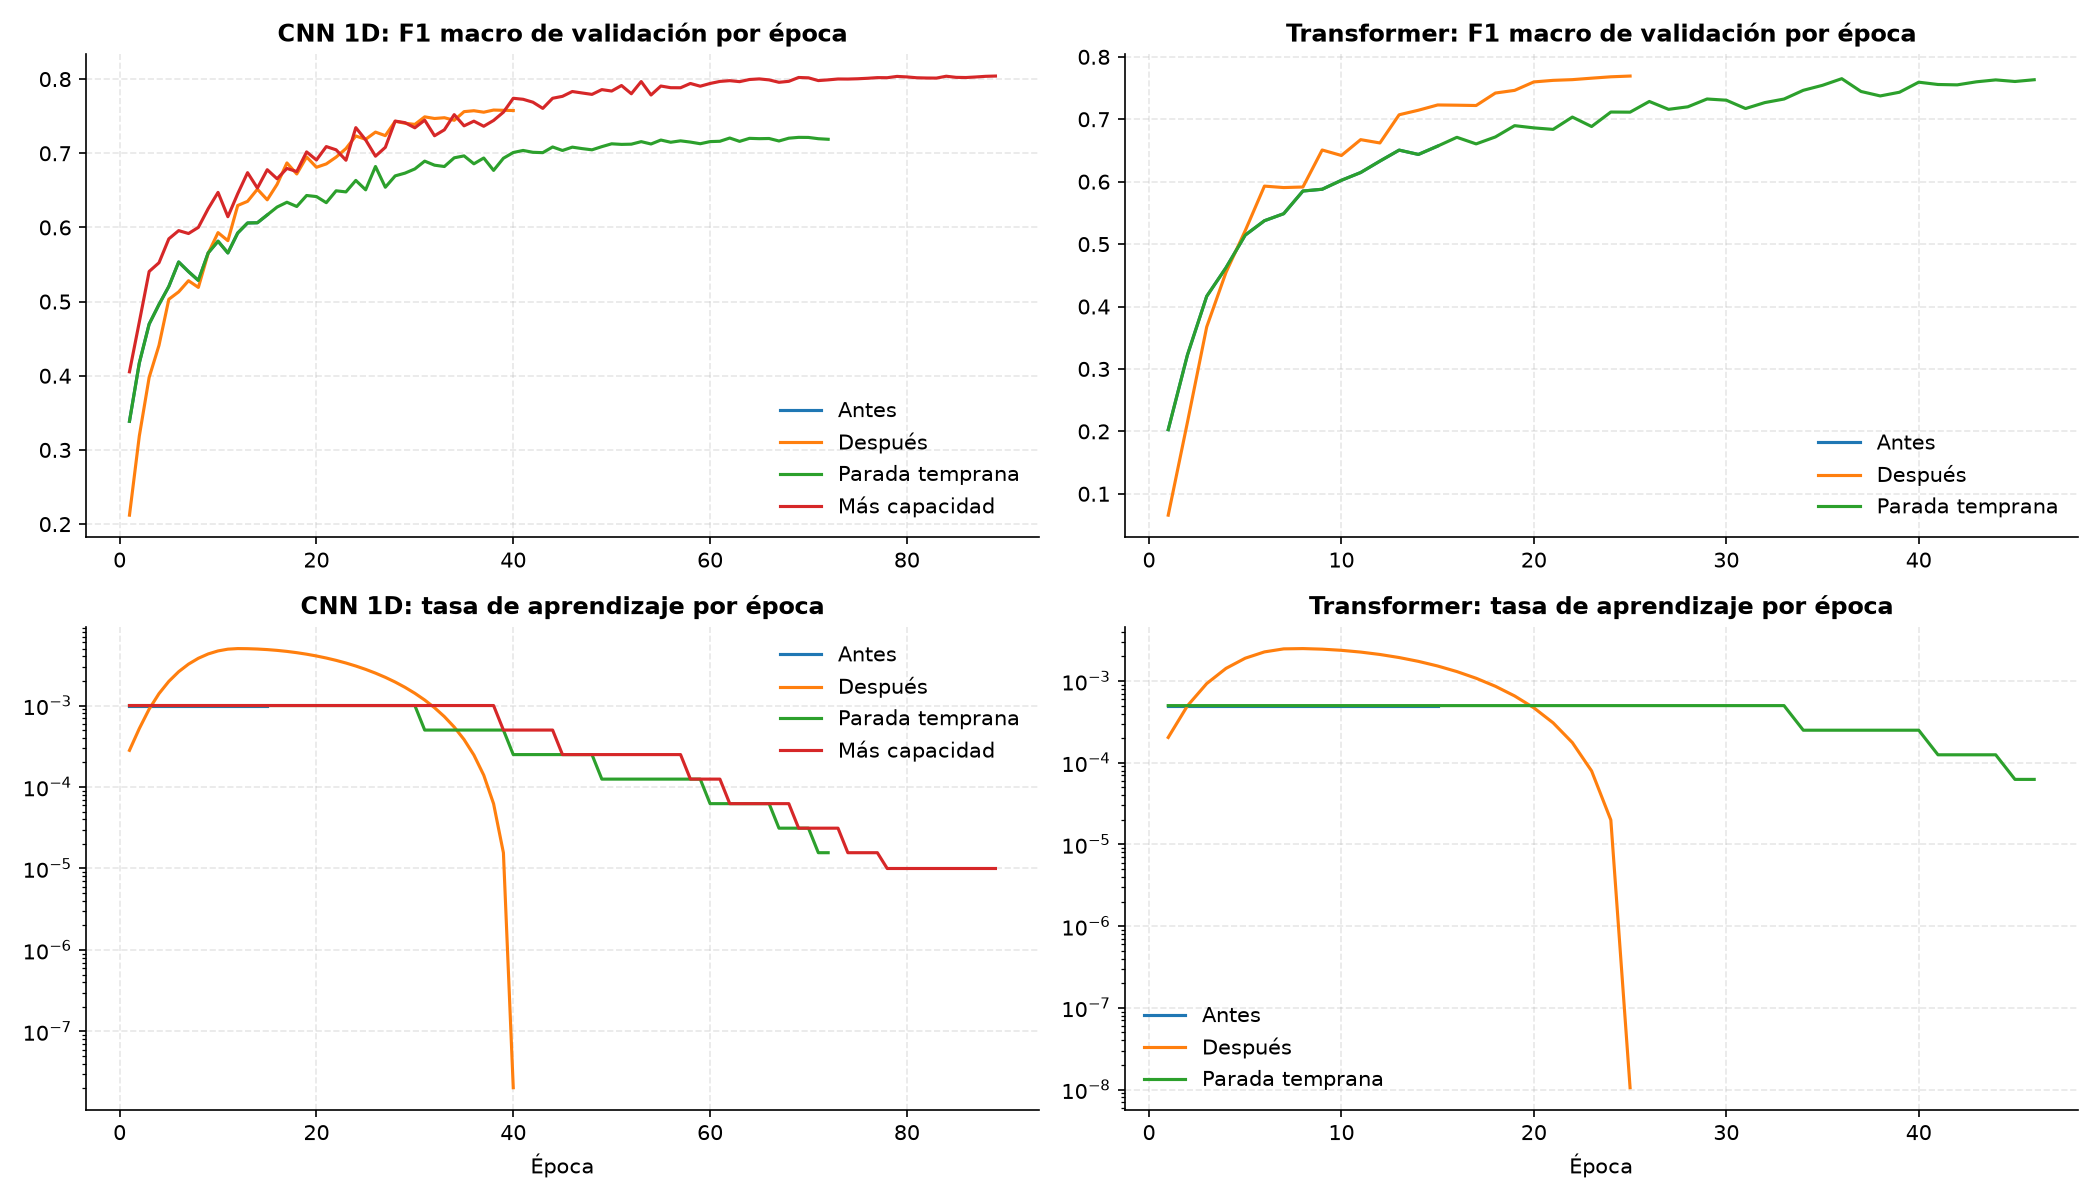

In [27]:
figura(DIAG / "comparacion_parada.png", ancho=1000)

**Lectura.** La parada temprana ahora actúa en las tres ejecuciones nuevas: la CNN se detuvo en la época 72 de 150, el
Transformer en la 46 de 100 y la CNN con más capacidad en la 89 de 150. El problema técnico que señaló la docente
quedó resuelto.

El resultado más interesante es que entrenar más, por sí solo, no mejoró las redes. La CNN bajó de 0,758 a 0,719 en
validación y el Transformer se mantuvo (de 0,769 a 0,763). En ambos casos el F1 de entrenamiento siguió por debajo de
0,80, lo que indica que la arquitectura no tenía capacidad para aprender más: el límite no eran las épocas.

Aumentar la capacidad, en cambio, sí funcionó. La CNN con el doble de canales sube a 0,804 en validación y a 0,791 en
octubre, unos 4,5 puntos más que en la semana 3. Su F1 de entrenamiento supera 0,80 y la brecha con validación (0,031)
sigue lejos del sobreajuste.

El diagnóstico automático todavía etiqueta a esta CNN como "subajuste" porque su mejor época fue la última. Sin
embargo, sus últimas mejoras fueron de 0,03 y 0,05 puntos, por debajo del mínimo fijado, y la tasa ya había llegado a
su valor mínimo. Se trata de una convergencia práctica: entrenar más daría ganancias insignificantes. El Transformer
con más capacidad no se evaluó por falta de tiempo, y queda como trabajo pendiente.

## 8. Conclusiones y limitaciones

**Conclusiones**

1. El modelo aporta valor real: supera al azar por más de 75 puntos de F1 macro, con un intervalo de confianza estrecho.
2. Es robusto frente a lo que suele ocurrir en una red: tolera variaciones del 10 % en tiempos y bytes y la deriva de
   dos meses. No lo es frente a datos faltantes, a cambios fuertes en la composición del tráfico, a poblaciones de
   flujos que no vio al entrenar ni al relleno deliberado de paquetes.
3. La exactitud no sirve para este problema: puede quedar intacta mientras el desempeño por categoría se derrumba.
4. De los hiperparámetros, el que realmente importa es `min_child_weight`. La configuración optimizada mejora a la
   versión 2 en 0,78 puntos en octubre, con significancia estadística confirmada por tres pruebas distintas.
5. Las redes estaban limitadas por su capacidad, no por la duración del entrenamiento.

**Limitaciones**

1. La búsqueda de Optuna alcanzó 41 de las 60 pruebas previstas por el tope de tiempo, y su límite de 400 rondas resultó
   corto.
2. La validación cruzada y Optuna usaron una submuestra de 60 000 flujos por costo de cómputo.
3. Octubre ya se había consultado antes de esta semana. Las decisiones se tomaron solo con validación, pero la prueba
   no es completamente virgen.
4. El relleno de paquetes vuelve inútil al clasificador, y ninguna mitigación basada en estas variables lo resolvería.
5. El Transformer con más capacidad quedó sin evaluar.

## Referencias

Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization
framework. En *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining*
(pp. 2623-2631). ACM. https://doi.org/10.1145/3292500.3330701

Bergstra, J., Bardenet, R., Bengio, Y., & Kégl, B. (2011). Algorithms for hyper-parameter optimization. En *Advances in
Neural Information Processing Systems* (Vol. 24, pp. 2546-2554).

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. En *Proceedings of the 22nd ACM SIGKDD
International Conference on Knowledge Discovery and Data Mining* (pp. 785-794). ACM. https://doi.org/10.1145/2939672.2939785

Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. En *Proceedings of the
34th International Conference on Machine Learning* (pp. 1321-1330). PMLR.

Hutter, F., Hoos, H., & Leyton-Brown, K. (2014). An efficient approach for assessing hyperparameter importance. En
*Proceedings of the 31st International Conference on Machine Learning* (pp. 754-762). PMLR.

Hynek, K., Luxemburk, J., Pešek, J., Čejka, T., & Šiška, P. (2024). CESNET-TLS-Year22: A year-spanning TLS network
traffic dataset from backbone lines. *Scientific Data, 11*, Artículo 1156. https://doi.org/10.1038/s41597-024-03927-4

McNemar, Q. (1947). Note on the sampling error of the difference between correlated proportions or percentages.
*Psychometrika, 12*(2), 153-157. https://doi.org/10.1007/BF02295996

Prechelt, L. (1998). Early stopping: But when? En G. B. Orr & K.-R. Müller (Eds.), *Neural networks: Tricks of the
trade* (pp. 55-69). Springer.

Weerts, H., Dudík, M., Edgar, R., Jalali, A., Lutz, R., & Madaio, M. (2023). Fairlearn: Assessing and improving fairness
of AI systems. *Journal of Machine Learning Research, 24*(257), 1-8.

Wilcoxon, F. (1945). Individual comparisons by ranking methods. *Biometrics Bulletin, 1*(6), 80-83.
https://doi.org/10.2307/3001968